## Credit Risk Machine Learning System

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("../data/CreditRisk.csv")

In [3]:
print('Data Shape',data.shape)

Data Shape (32581, 12)


In [4]:
print('Missing Values:\n',data.isna().mean()*100)

Missing Values:
 person_age                    0.000000
person_income                 0.000000
person_home_ownership         0.000000
person_emp_length             2.747000
loan_intent                   0.000000
loan_grade                    0.000000
loan_amnt                     0.000000
loan_int_rate                 9.563856
loan_status                   0.000000
loan_percent_income           0.000000
cb_person_default_on_file     0.000000
cb_person_cred_hist_length    0.000000
dtype: float64


In [5]:
print(f'Duplicate Values: {data.duplicated().sum()}')

Duplicate Values: 165


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB


In [7]:
# checking class imbalance
data['loan_status'].value_counts()/len(data)*100

loan_status
0    78.183604
1    21.816396
Name: count, dtype: float64

## Splitting data in Independent and Dependent features

In [8]:
x = data.drop('loan_status',axis=1)
y = data['loan_status']

In [9]:
x.describe(include='number').T

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


In [10]:
data[data['person_age'] > 100]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


## Univariate analysis

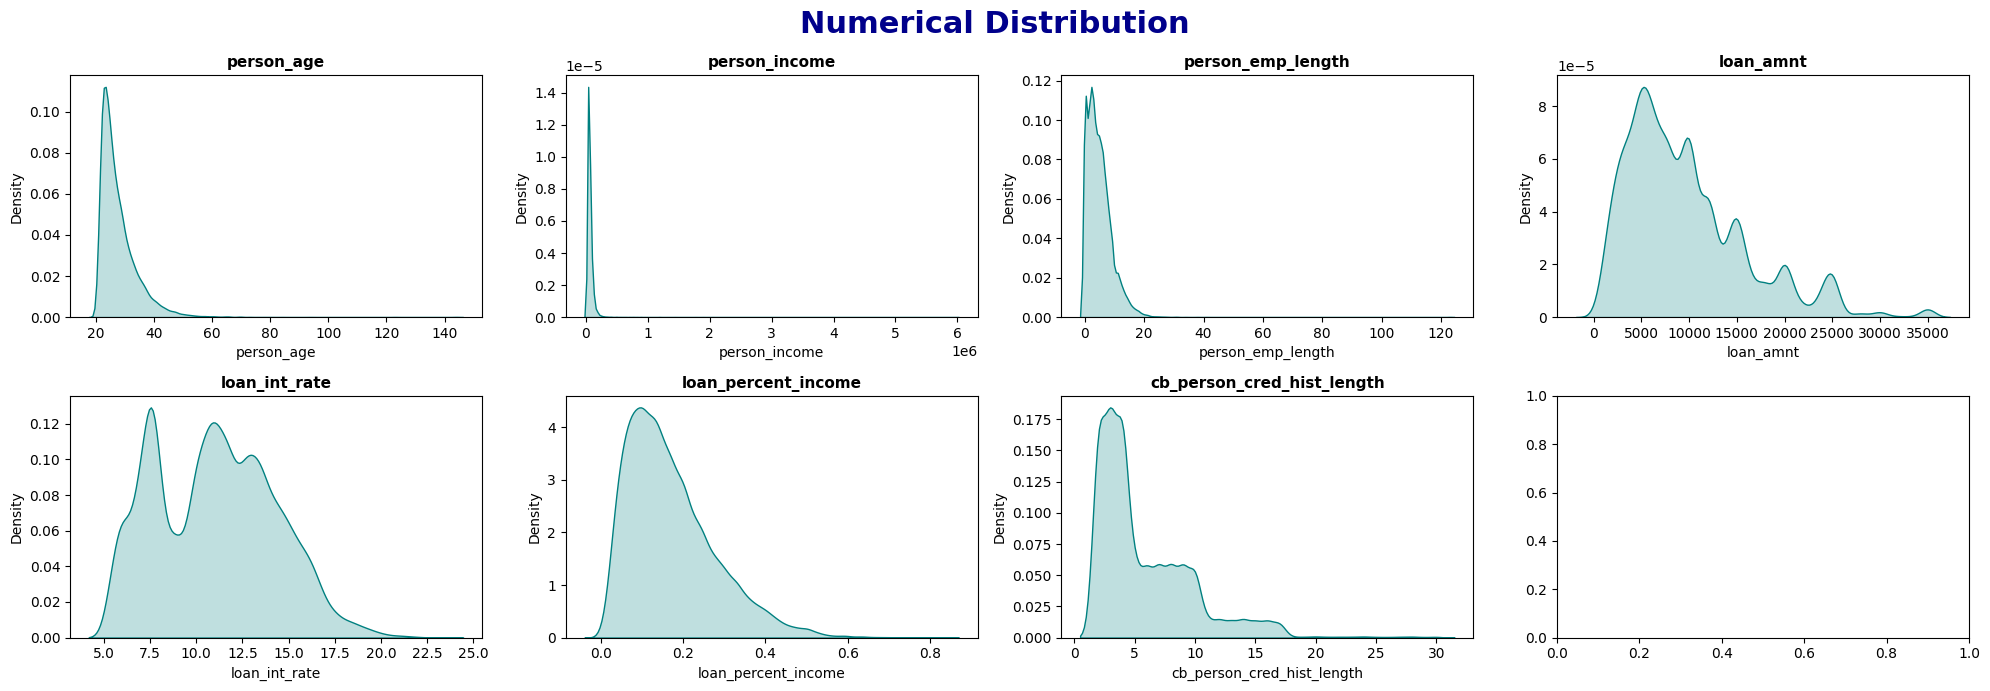

In [11]:
#Extracting numerical columns.
num_cols = x.select_dtypes(include='number').columns.to_list()
fig , axes = plt.subplots(2,4,figsize=(20,7))
plt.suptitle('Numerical Distribution',fontsize=22,fontweight='bold',color='darkblue')
axes = axes.flatten()
for i ,cols in enumerate(num_cols):
  sns.kdeplot(x = x[cols],fill=True,ax = axes[i],color='teal')
  axes[i].set_title(f'{cols}',fontsize = 11,fontweight='bold')
plt.tight_layout()
plt.show()

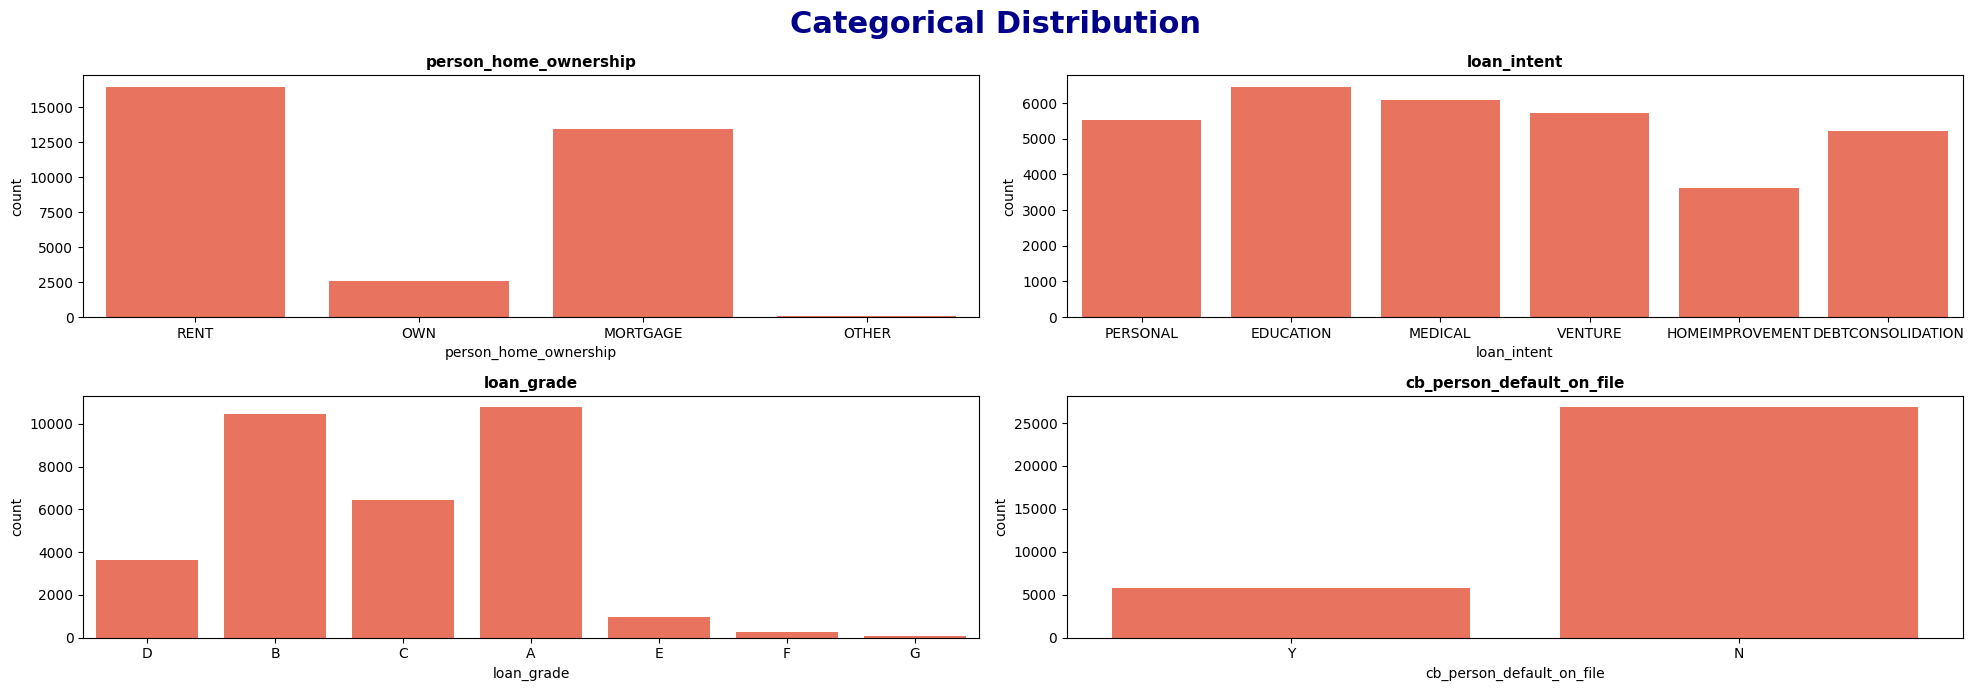

In [12]:
#Extracting categorical columns.
cat_cols = x.select_dtypes(include=['object','str']).columns.to_list()
fig , axes = plt.subplots(2,2,figsize=(20,7))
plt.suptitle('Categorical Distribution',fontsize=22,fontweight='bold',color='darkblue')
axes = axes.flatten()
for i ,cols in enumerate(cat_cols):
  sns.countplot(x = x[cols],fill=True,ax = axes[i],color='tomato')
  axes[i].set_title(f'{cols}',fontsize = 11,fontweight='bold')
plt.tight_layout()
plt.show()

## Missing Value Handling

In [13]:
# Using Z-Score method.
data['loan_int_rate'] = data['loan_int_rate'].fillna(data['loan_int_rate'].median())
data.dropna(inplace=True)
print('Missing Value handled Successfully')

Missing Value handled Successfully


In [14]:
print(f'new data shape: {data.shape}')

new data shape: (31686, 12)


## Outliers Handling

In [15]:
Q1 = data[num_cols].quantile(0.25)
Q3 = data[num_cols].quantile(0.75)
IQR=Q3-Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
((data[num_cols] < lower_bound) | (data[num_cols] > upper_bound)).sum()

person_age                    1460
person_income                 1464
person_emp_length              853
loan_amnt                     1636
loan_int_rate                   58
loan_percent_income            615
cb_person_cred_hist_length    1116
dtype: int64

In [16]:
# capping
data[num_cols] = np.where(data[num_cols]> upper_bound,upper_bound,
                          np.where(data[num_cols]< lower_bound,lower_bound,data[num_cols]))
print('Outliers capping Successfully!!')

Outliers capping Successfully!!


In [17]:
data[data['person_age']>100]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length


## Bivariate Analysis

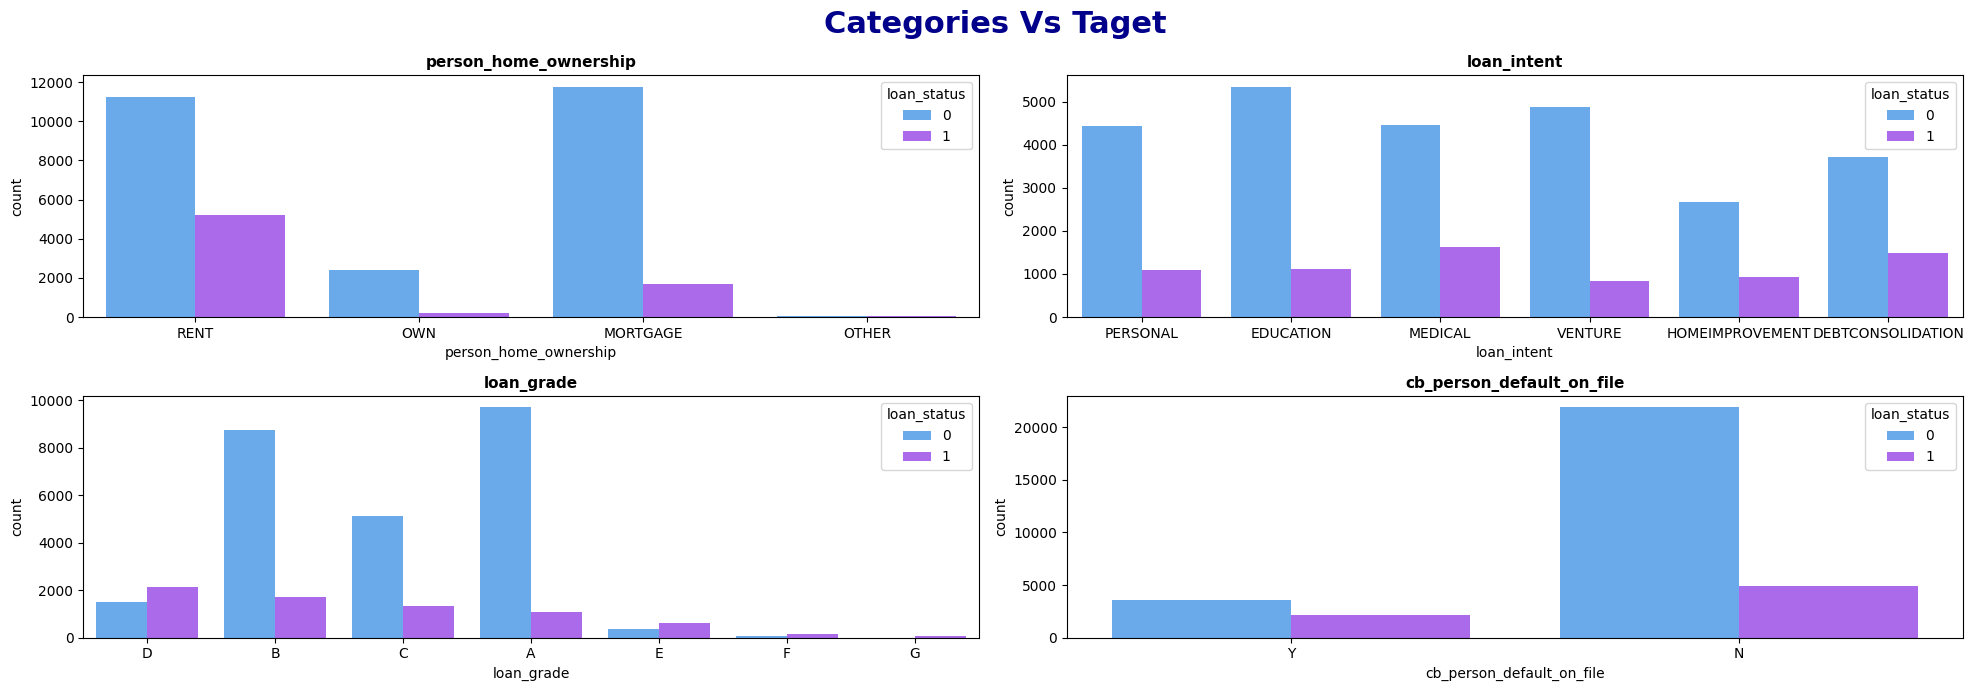

In [18]:
fig , axes = plt.subplots(2,2,figsize=(20,7))
plt.suptitle('Categories Vs Taget',fontsize=22,fontweight='bold',color='darkblue')
axes = axes.flatten()
for i ,cols in enumerate(cat_cols):
  sns.countplot(x = x[cols],hue=y,fill=True,ax = axes[i],palette='cool')
  axes[i].set_title(f'{cols}',fontsize = 11,fontweight='bold')
plt.tight_layout()
plt.show()

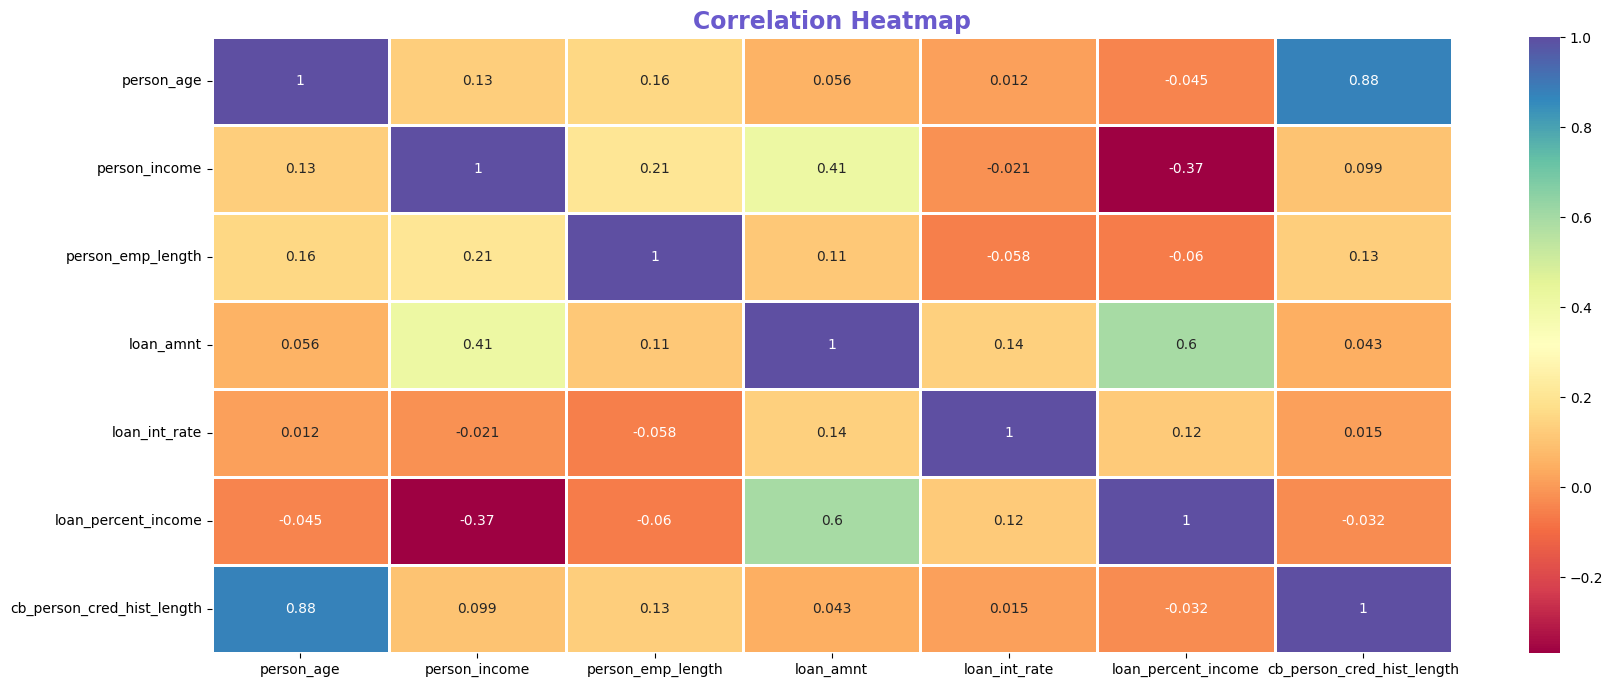

In [19]:
plt.figure(figsize=(20,8))
corr_matrix = data[num_cols].corr()
sns.heatmap(corr_matrix,annot=True,cmap='Spectral',linewidths=0.9)
plt.title('Correlation Heatmap',fontsize=17,fontweight = 'bold',color = 'slateblue')
plt.show()

In [20]:
## VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_data = pd.DataFrame()
vif_data["feature"] = num_cols
vif_data["VIF"] = [variance_inflation_factor(data[num_cols].values, i) for i in range(len(num_cols))]
vif_data

,feature,VIF
0,person_age,4.346835
1,person_income,4.247927
2,person_emp_length,1.070321
3,loan_amnt,5.707416
4,loan_int_rate,1.032916
5,loan_percent_income,5.417918
6,cb_person_cred_hist_length,4.293841


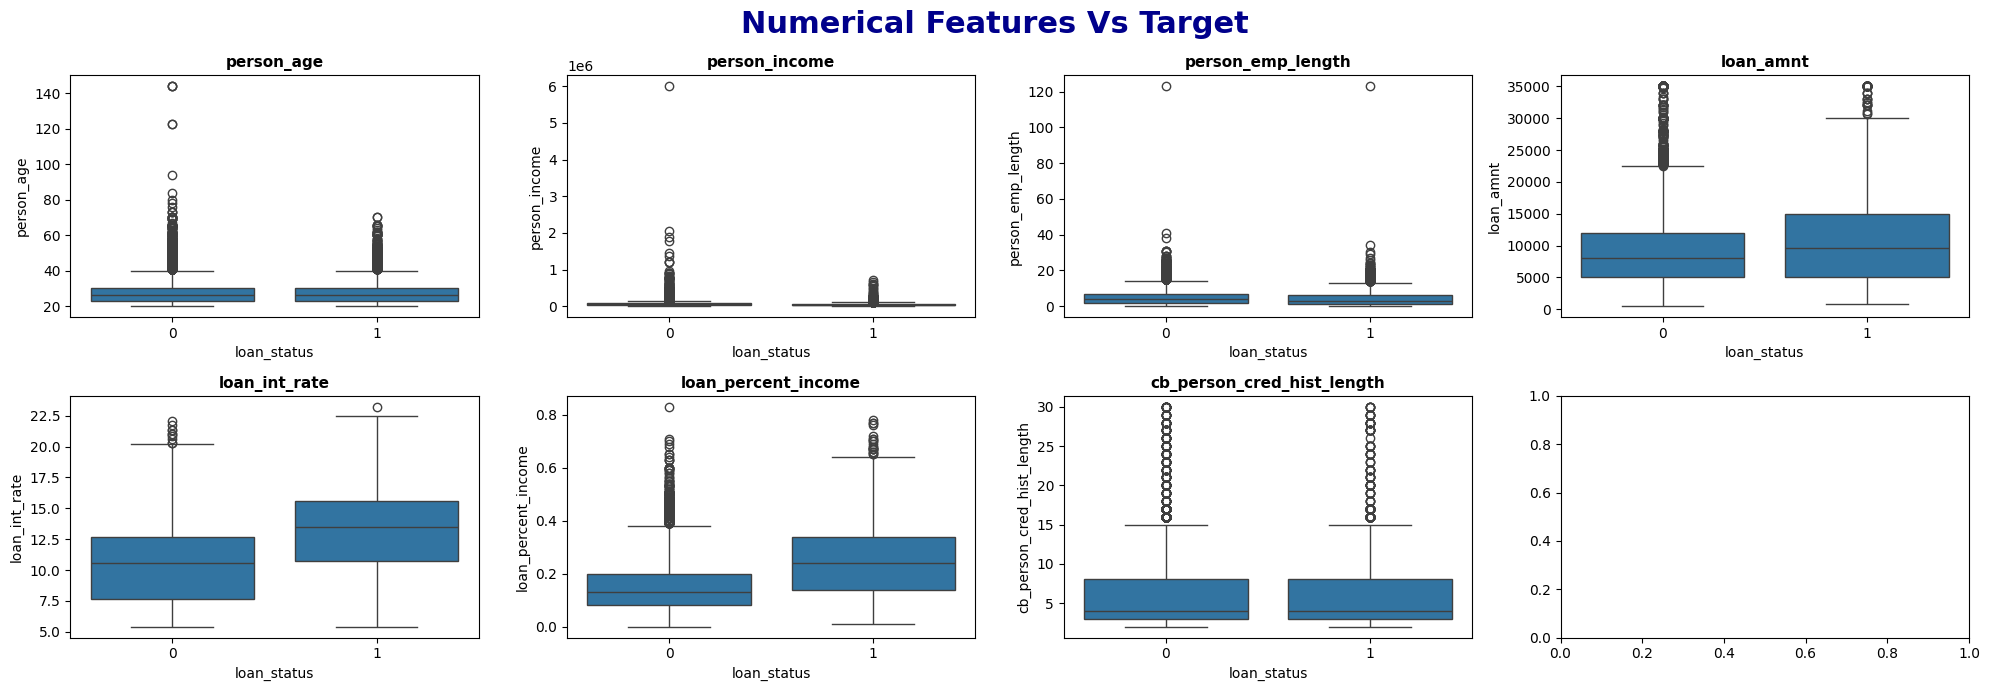

In [21]:
num_cols = x.select_dtypes(include='number').columns.to_list()
fig , axes = plt.subplots(2,4,figsize=(20,7))
plt.suptitle('Numerical Features Vs Target',fontsize=22,fontweight='bold',color='darkblue')
axes = axes.flatten()
for i ,cols in enumerate(num_cols):
  sns.boxplot(y = x[cols],x=y,ax = axes[i])
  axes[i].set_title(f'{cols}',fontsize = 11,fontweight='bold')
plt.tight_layout()
plt.show()

## Spliting Data into Train and Testing

In [22]:
from sklearn.model_selection import  train_test_split
from sklearn.compose import  ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [23]:
x_train , x_test ,y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [24]:
x_train.shape,x_test.shape

((26064, 11), (6517, 11))

In [25]:
# 0 -> No
# 1 -> 1 Yes
neg , pos = np.bincount(y_train)
scale_weights = neg/pos

In [26]:
num_cols = x_train.select_dtypes(include='number').columns.to_list()
cat_cols = x_train.select_dtypes(include=['object','str']).columns.to_list()

Preprocessing for Logistic Regression (Baseline)

In [27]:
preprocessor_lr = ColumnTransformer(
    transformers=[
        # Pipeline -> For Numerical Cols.
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
            ('Scaler',StandardScaler())
        ]),num_cols),
        # Pipeline -> Categorical Cols.
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='most_frequent')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),cat_cols)
    ])

In [28]:
from sklearn.linear_model import LogisticRegression

## Preprocessing for XGBoost and RandomForest

In [29]:
# No scaling required.
preprocessor_xg_rf = ColumnTransformer(
    transformers=[
        # Pipeline -> For Numerical Cols.
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median'))
        ]),num_cols),
        # Pipeline -> Categorical Cols.
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='most_frequent')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),cat_cols)
    ])

In [30]:
# we to evaluate logistic model and XGB model
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,precision_recall_curve
def evaluate_model(model_name:str , model,X_test,y_test,threshold=None):
  y_pred_prob = model.predict_proba(X_test)[:,1]
  if threshold != None:
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(X_test)


  # metrices:
  accuracy = accuracy_score(y_test,y_pred) # Overall Model's Performance
  precision = precision_score(y_test,y_pred) # Of the ones I picked, how many are correctly  right ?
  recall = recall_score(y_test,y_pred)# Out of everything that was really there, how much did we manage to find.
  f1 = f1_score(y_test,y_pred)# hormonic mean of precision and recall.
# confusion matrix:
  cm = confusion_matrix(y_test,y_pred)
  classification_rep = classification_report(y_test,y_pred)
  sns.heatmap(cm)
  print(f'{model_name} Performance:')
  print(f'Accuracy: {accuracy:.3f}')
  print(f'Precision: {precision:.3f}')
  print(f'Recall: {recall:.3f}')
  print(f'F1: {f1:.3f}')
  if threshold != None: 
      print(f'Best theshold: {threshold:.2f}')
  print()
  print(classification_rep)
  print()
  # ploting confusions matrix
  sns.heatmap(cm,annot=True,fmt='d')
  plt.title(f'{model_name} Confusion Matrix')
  plt.xlabel('Predicted Labels')
  plt.ylabel('True Labels')
  plt.show()
  print()

  # ploting Precision Recall curve
  precisons , recall , threshold = precision_recall_curve(y_test,y_pred_prob)
  plt.plot(recall,precisons,color='red')
  plt.title(f'{model_name} Precision-Recall Curve')
  plt.xlabel('Recall')
  plt.ylabel('Precision')
  plt.show()

In [31]:
from sklearn.model_selection import StratifiedKFold,cross_validate

In [32]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring = {'roc_auc':'roc_auc',
           'accuracy':'accuracy',
           'precision':'precision',
           'recall':'recall',
           'f1':'f1'
           }

## Baseline Model - Logistic Regression

In [33]:
lr_model = Pipeline(steps=[
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(class_weight="balanced"))])

In [34]:
lr_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [35]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier
rf_model = Pipeline(steps=[
    ('preprocessor',preprocessor_xg_rf),
    ('classifier',RandomForestClassifier(class_weight="balanced"))
])

In [36]:
rf_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [37]:
# XGB Model
from xgboost import XGBClassifier
xgb_model= Pipeline(steps=[
    ('preprocessor',preprocessor_xg_rf),
    ('classifier',XGBClassifier(max_depth = 5,learning_rate=0.1,scale_pos_weight=scale_weights))
])

In [38]:
xgb_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [39]:
for cv_name , pipe in [("Logistic Regression" ,lr_model),
                       ("Random Forest",rf_model),
                  ('XGBoost',xgb_model)]:
                  cv_results = cross_validate(pipe,x_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
                  print(cv_name)
                  print()
                  print(f'ROC-AUC:{cv_results["test_roc_auc"].mean():.3f}')
                  print(f'Accuracy:{cv_results["test_accuracy"].mean():.3f}')
                  print(f'Precision:{cv_results["test_precision"].mean():.3f}')
                  print(f'Recall:{cv_results["test_recall"].mean():.3f}')
                  print(f'F1:{cv_results["test_f1"].mean():.3f}')
                  print('='*50)

Logistic Regression

ROC-AUC:0.870
Accuracy:0.810
Precision:0.546
Recall:0.774
F1:0.640
Random Forest

ROC-AUC:0.929
Accuracy:0.933
Precision:0.971
Recall:0.712
F1:0.822
XGBoost

ROC-AUC:0.939
Accuracy:0.906
Precision:0.781
Recall:0.788
F1:0.785


Logistic Regression Performance:
Accuracy: 0.814
Precision: 0.551
Recall: 0.780
F1: 0.646

              precision    recall  f1-score   support

           0       0.93      0.82      0.87      5095
           1       0.55      0.78      0.65      1422

    accuracy                           0.81      6517
   macro avg       0.74      0.80      0.76      6517
weighted avg       0.85      0.81      0.82      6517




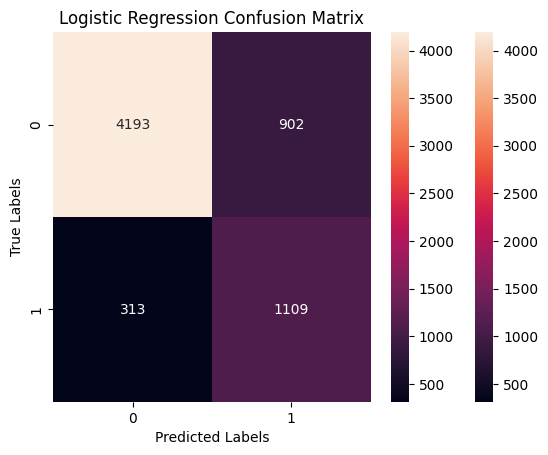

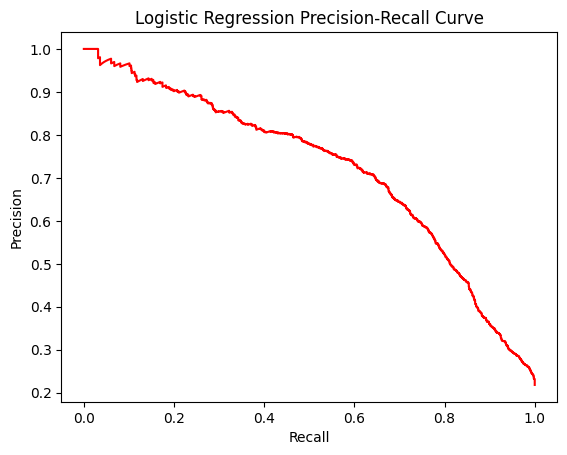

In [40]:
evaluate_model('Logistic Regression',lr_model,x_test,y_test)

Random Forest Performance:
Accuracy: 0.934
Precision: 0.978
Recall: 0.712
F1: 0.824

              precision    recall  f1-score   support

           0       0.93      1.00      0.96      5095
           1       0.98      0.71      0.82      1422

    accuracy                           0.93      6517
   macro avg       0.95      0.85      0.89      6517
weighted avg       0.94      0.93      0.93      6517




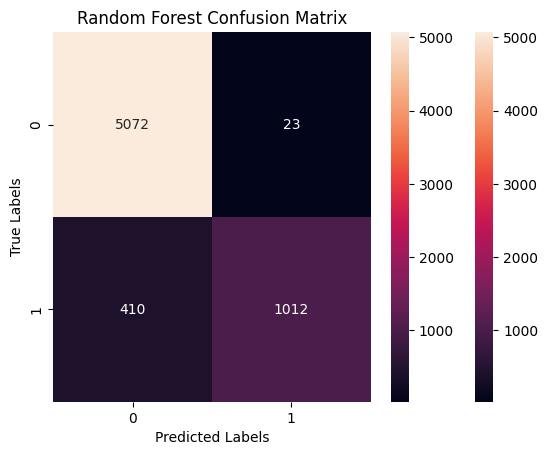

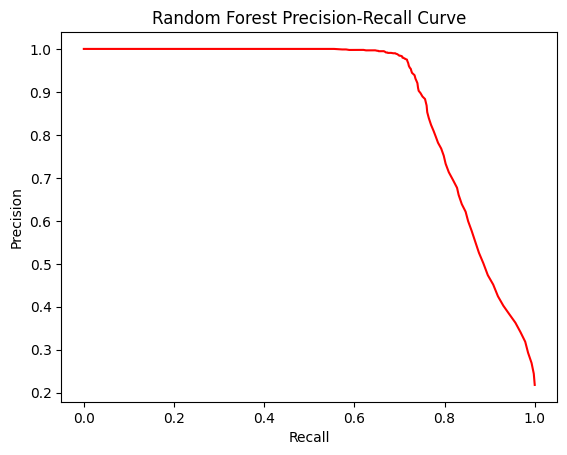

In [41]:
evaluate_model('Random Forest',rf_model,x_test,y_test)

XGBoost Performance:
Accuracy: 0.906
Precision: 0.785
Recall: 0.783
F1: 0.784

              precision    recall  f1-score   support

           0       0.94      0.94      0.94      5095
           1       0.79      0.78      0.78      1422

    accuracy                           0.91      6517
   macro avg       0.86      0.86      0.86      6517
weighted avg       0.91      0.91      0.91      6517




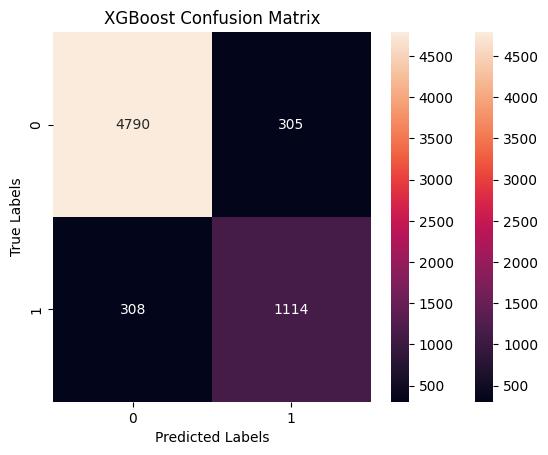

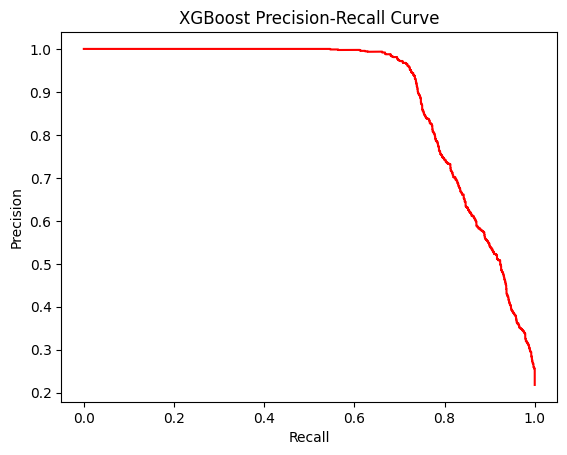

In [42]:
# Evaluate xgboost model
evaluate_model('XGBoost',xgb_model,x_test,y_test)

## Hyperperameter Tuning

In [43]:
from scipy.stats import randint

'''
Tuning Random Forest
Goal: Increasing recall without much compromising with precision.
'''
param_grid_rf = {
    'classifier__n_estimators': randint(200,600),
    'classifier__max_depth': [None, 5, 8, 10, 12, 15],
    'classifier__min_samples_split': randint(2, 15),
    'classifier__min_samples_leaf': randint(1, 15),
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__bootstrap': [True, False],
    'classifier__class_weight':['balanced',None,'balanced_subsample'],
    'classifier__criterion':['gini','entropy'],
}

In [44]:
from sklearn.model_selection import RandomizedSearchCV

random_search_rf = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid_rf,
    n_iter=30,
    scoring="average_precision",
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

In [45]:
random_search_rf.fit(x_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...'balanced'))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__bootstrap': [True, False], 'classifier__class_weight': ['balanced', None, ...], 'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': [None, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` f

In [46]:
random_search_rf.best_params_

{'classifier__bootstrap': False,
 'classifier__class_weight': 'balanced',
 'classifier__criterion': 'entropy',
 'classifier__max_depth': None,
 'classifier__max_features': 'log2',
 'classifier__min_samples_leaf': 1,
 'classifier__min_samples_split': 11,
 'classifier__n_estimators': 251}

In [47]:
y_pred = random_search_rf.predict(x_test)

Random forest Performance:
Accuracy: 0.927
Precision: 0.909
Recall: 0.741
F1: 0.817

              precision    recall  f1-score   support

           0       0.93      0.98      0.95      5095
           1       0.91      0.74      0.82      1422

    accuracy                           0.93      6517
   macro avg       0.92      0.86      0.89      6517
weighted avg       0.93      0.93      0.92      6517




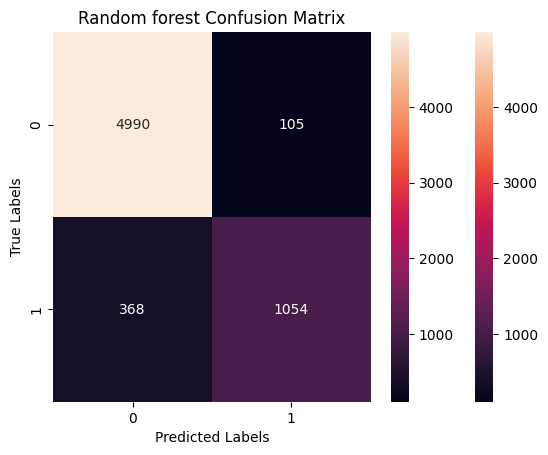

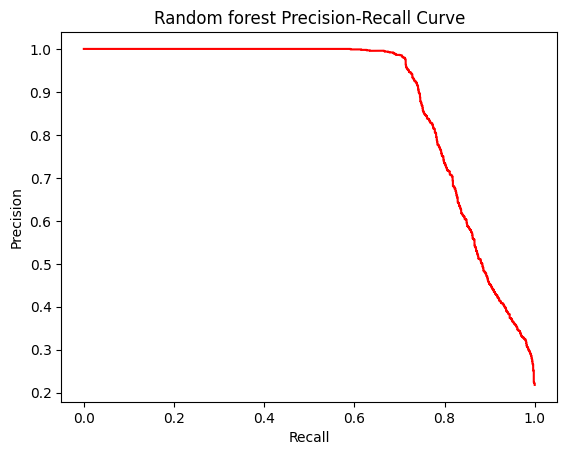

In [48]:
# after hyperparameter tuning.
evaluate_model('Random forest',random_search_rf,x_test,y_test)

In [51]:
from scipy.stats import randint, loguniform, uniform

"""
Tuning XGBoost
Goal: Minimizing errors"""
param_dist_xgb = {
    "classifier__n_estimators": randint(200, 800),

    "classifier__learning_rate": loguniform(0.01, 0.2),

    "classifier__max_depth": randint(3, 8),

    "classifier__min_child_weight": randint(1, 10),

    "classifier__subsample": uniform(0.6, 0.4),

    "classifier__colsample_bytree": uniform(0.6, 0.4),

    "classifier__gamma": uniform(0, 0.5),
    "classifier__reg_alpha": loguniform(1e-3, 10),

    "classifier__reg_lambda": loguniform(1, 20),

    "classifier__scale_pos_weight": [2.5,3.0,3.16,3.5,4.0]
}
# lower gamma -> more splits ->complex tree -> higher overfitting risk
# higher gamma -> lower splits -> simpler tree -> lower overfitting risk


In [52]:
random_search_xgb= RandomizedSearchCV(
                   xgb_model,
                   param_dist_xgb,
                   n_iter = 30,
                   cv= cv,
                   scoring = 'average_precision',
                   verbose = 1,
                   n_jobs = -1)

In [53]:
random_search_xgb.fit(x_train,y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': <scipy.stats....0023EBB035940>, 'classifier__gamma': <scipy.stats....0023EBB037BB0>, 'classifier__learning_rate': <scipy.stats....0023EBB183B10>, 'classifier__max_depth': <scipy.stats....0023EBB12DE50>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits

In [54]:
random_search_xgb.best_params_

{'classifier__colsample_bytree': np.float64(0.9300079740164788),
 'classifier__gamma': np.float64(0.4997758493532982),
 'classifier__learning_rate': np.float64(0.05158330843896232),
 'classifier__max_depth': 7,
 'classifier__min_child_weight': 2,
 'classifier__n_estimators': 434,
 'classifier__reg_alpha': np.float64(1.1531582446235282),
 'classifier__reg_lambda': np.float64(2.6700116886242626),
 'classifier__scale_pos_weight': 3.0,
 'classifier__subsample': np.float64(0.7968428705367974)}

In [55]:
y_pred = random_search_xgb.predict(x_test)

XGBoost Performance:
Accuracy: 0.929
Precision: 0.878
Recall: 0.784
F1: 0.828

              precision    recall  f1-score   support

           0       0.94      0.97      0.96      5095
           1       0.88      0.78      0.83      1422

    accuracy                           0.93      6517
   macro avg       0.91      0.88      0.89      6517
weighted avg       0.93      0.93      0.93      6517




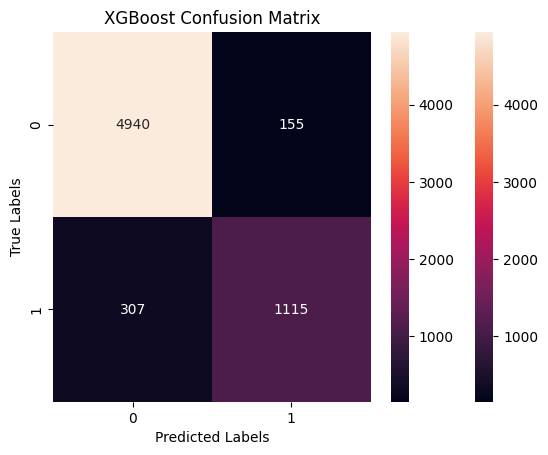

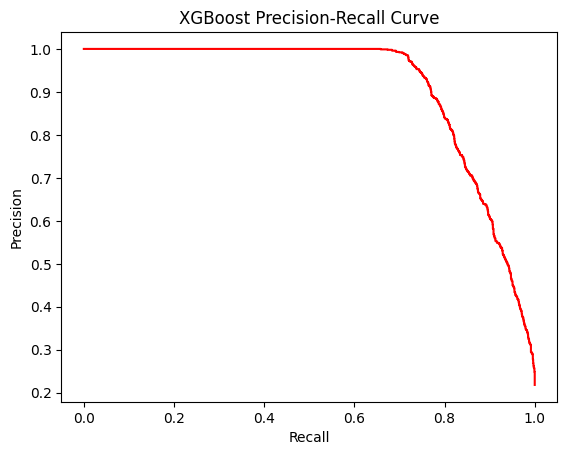

In [56]:
# after hyperparameter tuning.
evaluate_model('XGBoost',random_search_xgb,x_test,y_test)

Random Forest Model  Performance:
Accuracy: 0.934
Precision: 0.979
Recall: 0.712
F1: 0.824
Best theshold: 0.64

              precision    recall  f1-score   support

           0       0.93      1.00      0.96      5095
           1       0.98      0.71      0.82      1422

    accuracy                           0.93      6517
   macro avg       0.95      0.85      0.89      6517
weighted avg       0.94      0.93      0.93      6517




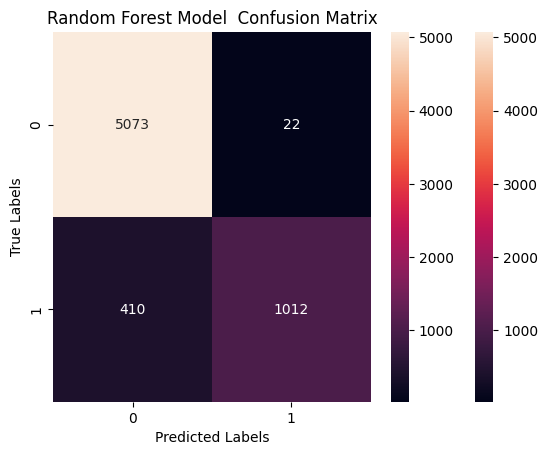

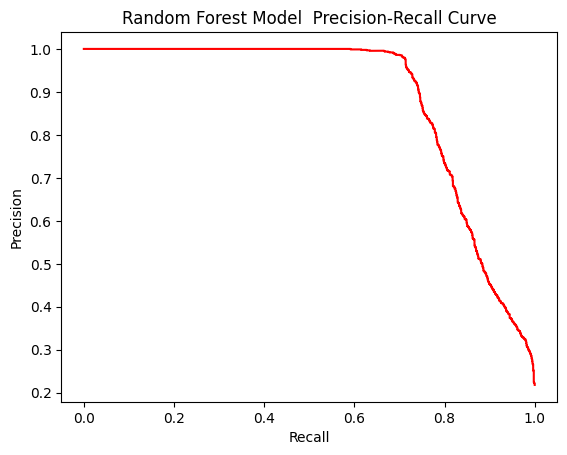

In [57]:
# for random forest
# get the probability  for class 1 from Random Forest
prob = random_search_rf.predict_proba(x_test)[:,1]
# for each threshold calculate Precision and recall
precision , recall , threshold = precision_recall_curve(y_test,prob)
# calculate f1 score for each threshold
f1 = 2*(precision * recall)/(precision + recall + 10e-9)
# get the threshold that produces the highest f1 -score
best_threshold = threshold[np.argmax(f1)]
# evaluate the Random Forest model .
evaluate_model('Random Forest Model ',random_search_rf,x_test,y_test,threshold=best_threshold)

XGB Model  Performance:
Accuracy: 0.935
Precision: 0.929
Recall: 0.760
F1: 0.836
Best theshold: 0.58

              precision    recall  f1-score   support

           0       0.94      0.98      0.96      5095
           1       0.93      0.76      0.84      1422

    accuracy                           0.94      6517
   macro avg       0.93      0.87      0.90      6517
weighted avg       0.93      0.94      0.93      6517




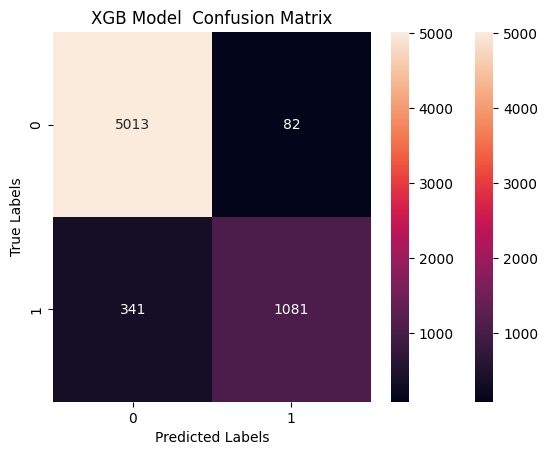

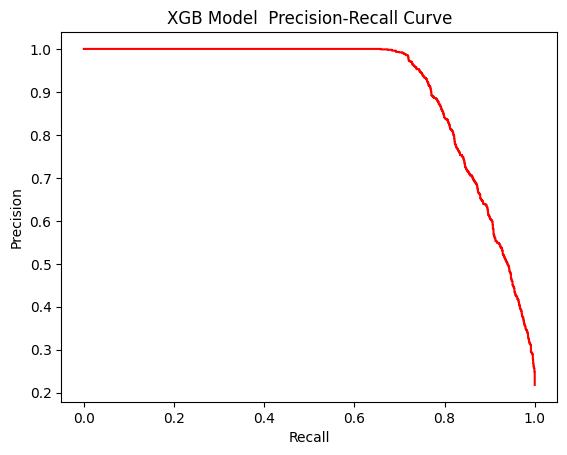

In [58]:
# For XGB
# get the probability  for class 1 from XGB
prob = random_search_xgb.predict_proba(x_test)[:,1]
# for each threshold calculate Precision and recall
precision , recall , threshold = precision_recall_curve(y_test,prob)
# calculate f1 score for each threshold
f1 = 2*(precision * recall)/(precision + recall + 10e-9)
# get the threshold that produces the highest f1 -score
best_threshold = threshold[np.argmax(f1)]
# evaluate the XGB model .
evaluate_model('XGB Model ',random_search_xgb,x_test,y_test,threshold=best_threshold)

## Probability Calibration

In [59]:
#1 . Calibrated XGB model
from sklearn.calibration import  CalibratedClassifierCV,calibration_curve
from sklearn.frozen import FrozenEstimator
calibrated_xgb = CalibratedClassifierCV(
    estimator = FrozenEstimator(random_search_xgb),
    method='sigmoid',
    cv = 10
    )
calibrated_xgb.fit(x_train,y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",FrozenEstimat... verbose=1))
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary ` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the column

XGB Model  Performance:
Accuracy: 0.935
Precision: 0.929
Recall: 0.760
F1: 0.836
Best theshold: 0.75

              precision    recall  f1-score   support

           0       0.94      0.98      0.96      5095
           1       0.93      0.76      0.84      1422

    accuracy                           0.94      6517
   macro avg       0.93      0.87      0.90      6517
weighted avg       0.93      0.94      0.93      6517




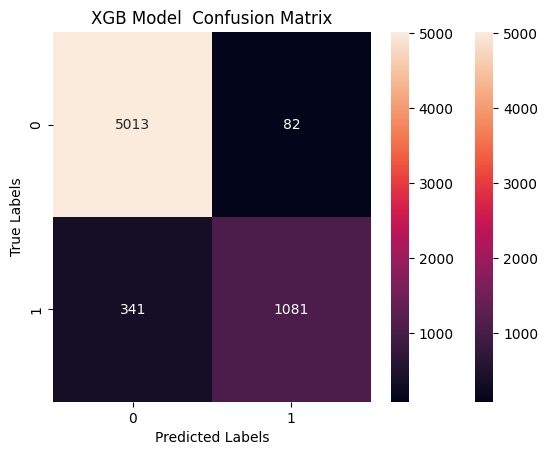

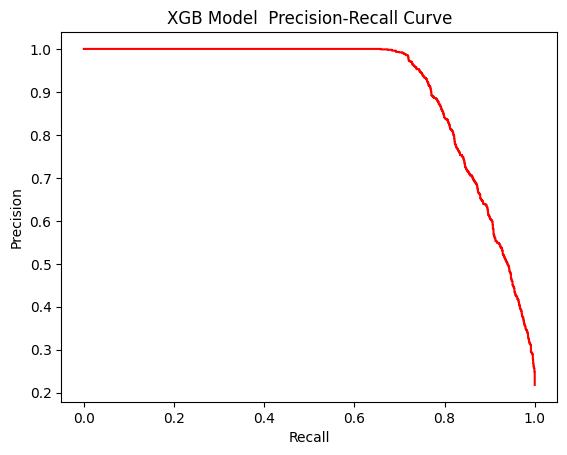

In [60]:
# For XGB
# get the probability  for class 1 from XGB
calibrated_prob = calibrated_xgb.predict_proba(x_test)[:,1]
# for each threshold calculate Precision and recall
precision , recall , threshold = precision_recall_curve(y_test,calibrated_prob)
# calculate f1 score for each threshold
f1 = 2*(precision * recall)/(precision + recall + 10e-9)
# get the threshold that produces the highest f1 -score
new_threshold = threshold[np.argmax(f1)]
# evaluate the XGB model .
evaluate_model('XGB Model ',calibrated_xgb,x_test,y_test,threshold=new_threshold)

In [61]:
#2. Get prob.
uncalibrated_prob = random_search_xgb.predict_proba(x_test)[:,1]
calibrated_prob = calibrated_xgb.predict_proba(x_test)[:,1]

In [62]:
#3. Create callibration curves.
actual_uncal,predicted_uncal= calibration_curve(y_test,uncalibrated_prob,n_bins=15)
actual_cal,predicted_cal = calibration_curve(y_test,calibrated_prob,n_bins=15)

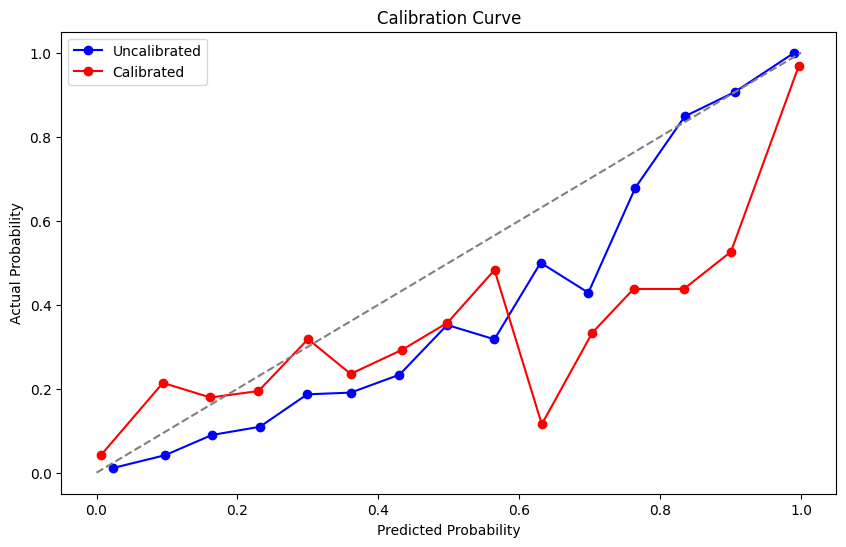

In [63]:
#4. plot
plt.figure(figsize=(10,6))
plt.plot(
    predicted_uncal,
    actual_uncal,
    marker='o',
    linestyle='-',
    color='blue',
    label='Uncalibrated'
)
plt.plot(
    predicted_cal,
    actual_cal,
    marker='o',
    linestyle='-',
    color='red',
    label='Calibrated'
    )
plt.plot([0,1],[0,1],linestyle='--',color='gray')
plt.xlabel('Predicted Probability')
plt.ylabel('Actual Probability')
plt.title('Calibration Curve')
plt.legend()

XGBoost Performance:
Accuracy: 0.929
Precision: 0.879
Recall: 0.784
F1: 0.829

              precision    recall  f1-score   support

           0       0.94      0.97      0.96      5095
           1       0.88      0.78      0.83      1422

    accuracy                           0.93      6517
   macro avg       0.91      0.88      0.89      6517
weighted avg       0.93      0.93      0.93      6517




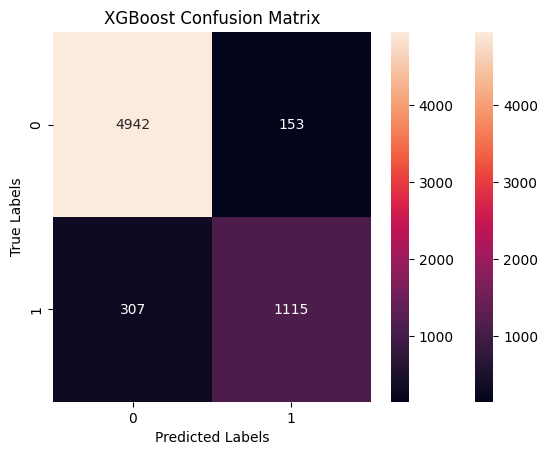

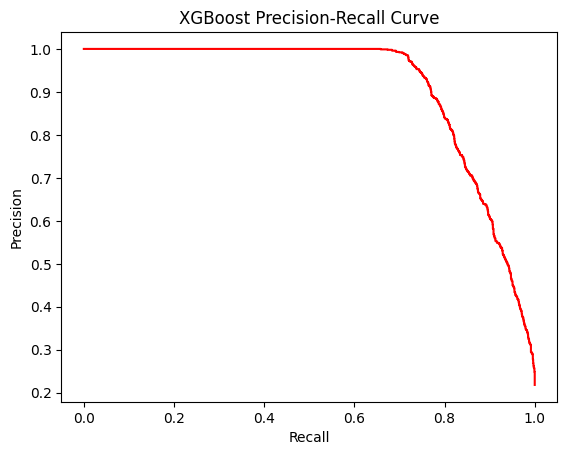

In [64]:
evaluate_model('XGBoost',calibrated_xgb,x_test,y_test)

## SHAP Interpretation - Global & Local

In [67]:
import shap
#1. Get the trained XGB classifier model out of the pipeline.
xgb_classifier = xgb_model.named_steps['classifier']
xgb_classifier

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets im

In [68]:
#2. Transform x_test using the same preprocessing used for training.
x_test_transformed = xgb_model.named_steps['preprocessor'].transform(x_test)

In [69]:
#3. Get features names after one-hot-encoding,so plots are readable.
feature_names = xgb_model.named_steps['preprocessor'].get_feature_names_out()

In [70]:
#4. Convert to a data frame for cleaner SHAP plots
x_test_df = pd.DataFrame(x_test_transformed,columns=feature_names)

In [71]:
#5. create SHAP explainer built for tree-based model.
explainer = shap.TreeExplainer(xgb_classifier)

In [72]:
#6. Calculate shap values for every row in the test set
shap_values = explainer.shap_values(x_test_df)

## Global Explanation

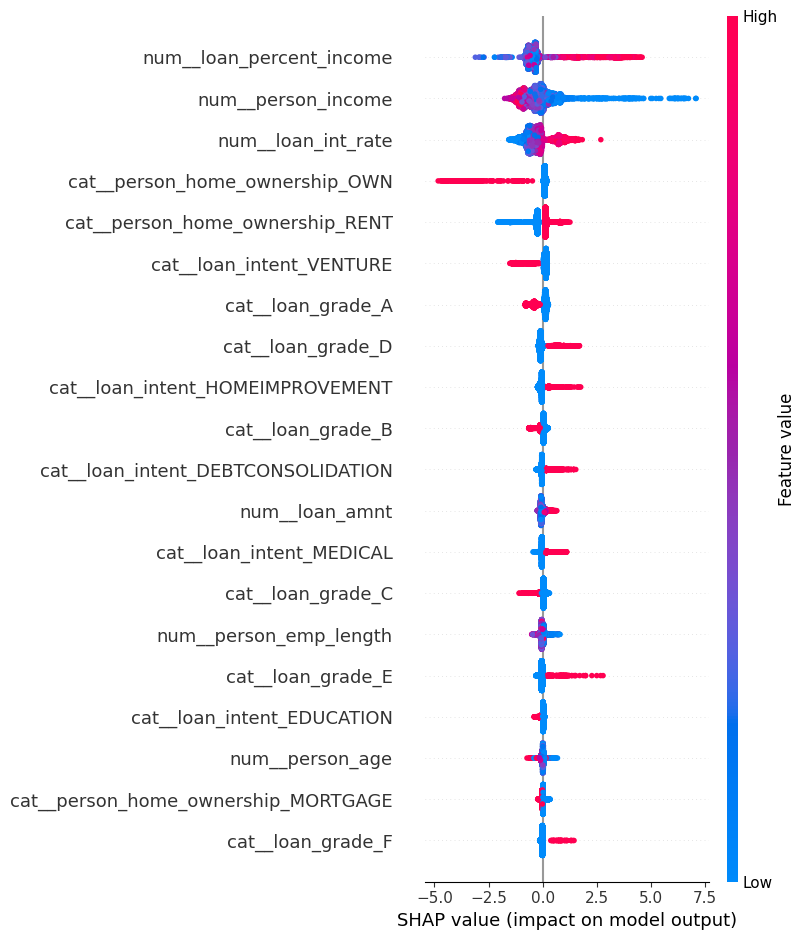

In [73]:
shap.summary_plot(shap_values,x_test_df)

## Analyzing False Positives & False Negatives.

In [74]:
# get prediction from best peforming model on the test set
y_pred = random_search_xgb.predict(x_test)

In [75]:
# create a dataframe to easily compare the actual and predicted values
result_df = x_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [76]:
# identify FP : model pred 1 , but actual 0
false_positives = result_df[(result_df['predicted'] == 1) & (result_df['actual'] == 0)]
# identify FN : model pred 0 , but actual 1
false_negatives = result_df[(result_df['predicted'] == 0) & (result_df['actual'] == 1)]

In [77]:
print(f'False Positives: {len(false_positives)}')
print(f'False Negatives: {len(false_negatives)}')

False Positives: 155
False Negatives: 307


## Saving Best Model

In [78]:
import joblib
joblib.dump(calibrated_xgb,'xgb_model.joblib')

['xgb_model.joblib']

In [79]:
joblib.dump(new_threshold,'best_threshold')

['best_threshold']

In [80]:
print(data['loan_grade'].unique().tolist())

['D', 'B', 'C', 'A', 'E', 'F', 'G']
